# Genuine fixed-point parameter search — no covariance mixtures

Use the original rho update, identity initialization, damping .25, covariance
eigenvalue bounds [1e-4,100] and pseudoinverse cutoff1e-6. **No Gram replacement,
manual correlation, covariance mixture, or direct optimization.**

Delta=1,2,5,10,20; with/without intercept. Auxiliary fits: exact LS, or unpenalized
logistic FISTA (8,12,16,20,30,50), L-BFGS (3,5,10,20), GD (8,16,30,50).
Save rho after 1,3,5,8,12,16,20,24,30,40 updates: 150 paths, 1500 snapshots.
Logistic auxiliary/posterior fits are either exactly matched or use FISTA16 as an
explicitly labeled alternative; LS auxiliary pairs with all logistic fit settings.
Pilot selection uses the auxiliary loss and includes the null. No truth is used.

Record every snapshot, raw-update eigenvalues, number of clipped eigenvalues,
and moment residual. Evaluate posterior curves for snapshots with absolute
correlation at least .001, plus the old rank3 control. This skips structurally
diagonal cases without pretending correlation validates an estimate. Screening
uses 512 integration draws. Final shortlisted posteriors use 1024 draws; a second
check reruns the **entire rho trajectory** with 1024 draws/seed42. The primary
trajectory used 512/seed123. Numerical sensitivity therefore includes estimation
and integration changes, not just likelihood evaluation at fixed rho.

Target: the earlier rank3 conditional curve. Shortlist the closest10 overall,
closest10 with absolute correlation>=.05, and leaders of the no-intercept and
matched-fit subsets. Display all shortlist results and top20 plots; mean TV
ranking has no P(1) bonus. Both main and rechecked correlations remain visible.
All settings/outcomes are retained. These are outcome-guided exploratory analyses,
not a proof of estimator accuracy or posterior calibration. 36 parallel jobs.


In [1]:
"""Fixed-point hyperparameter search: no external covariance mixtures."""
from tools.myocardial_final_redo import *
from tools.myocardial_direct_moment_experiment import ls_fit,state_at
from WERM.myocardial_finite_intercept import finite_intercept_fit
from WERM.myocardial_no_intercept_solvers import fit_column
from tools.myocardial_best_ones import curve_metrics

DELTAS_SEARCH=(1,2,5,10,20)
STEPS=(1,3,5,8,12,16,20,24,30,40)
FITS=[('fista',b) for b in (8,12,16,20,30,50)]+[('lbfgs',b) for b in (3,5,10,20)]+[('gd',b) for b in (8,16,30,50)]
BASE=Path('results/myocardial_final_redo_e3d965cc4b9b')


def correlation(rho):
    return float(rho[0,1]/np.sqrt(rho[0,0]*rho[1,1]))


def update_rho(rho,S,state):
    inverse=np.linalg.pinv(state['lambda'],rcond=1e-6)
    raw=inverse.T@(S-state['kappa'])@inverse
    eigenvalues=np.linalg.eigvalsh((raw+raw.T)/2)
    result=project_covariance(.75*rho+.25*project_covariance(raw))
    return result,eigenvalues,int(np.sum(eigenvalues<1e-4))


def prepare(delta,intercept,X,y,locations,root):
    name=f'd{delta}_int{int(intercept)}';path=root/f'fits_{name}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    eta,prior,phi=configuration_prior(len(y),locations[(locations>=delta)&(locations<=len(y)-delta)])
    fits={'LS':ls_fit(X,y,phi,intercept)}
    for method,budget in FITS:
        if intercept:fit=finite_intercept_fit(X,y,phi,method,budget)
        else:
            cols=[fit_column(X,y,w,method,budget) for w in phi]
            B=np.column_stack([c['coef'] for c in cols]);theta=X@B
            V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
            fit=dict(theta=theta,V=V,b=b,checks=cols)
        fits[f'{method}{budget}']=fit
    result=dict(name=name,Delta=delta,intercept=intercept,setting=dict(eta=eta,prior=prior,phi=phi),
        fits=fits,delta=len(y)/X.shape[1],rate=float(y.mean()),spec=dict(intercept=intercept))
    atomic_save(path,result);return result


def rho_path_search(setting,auxiliary,y,root,power=9,seed=123,max_step=40):
    label=f"{setting['name']}_{auxiliary}_q{power}_seed{seed}_steps{max_step}"
    path=root/f'rho_{label}.pkl';partial=root/f'rho_{label}_partial.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    try:
        fit=setting['fits'][auxiliary];loss='squared' if auxiliary=='LS' else 'logistic'
        pilot_eta,psi=pilot(fit['theta'],y,setting['setting']['eta'],loss)
        S=fit['V'].T@fit['V']/len(y);prepared=dict(setting,loss=loss)
        saved=pickle.load(partial.open('rb')) if partial.exists() else dict(rho=np.eye(2),iteration=0,records=[],trace=[])
        rho=saved['rho'];records=saved['records'];trace=saved['trace']
        for it in range(saved['iteration']+1,max_step+1):
            state=state_at(prepared,rho,psi,power=power,seed=seed)
            rho,raw_eigs,clipped=update_rho(rho,S,state)
            trace.append(dict(iteration=it,raw_eigenvalues=raw_eigs,clipped=clipped,correlation=correlation(rho)))
            if it in STEPS:
                check=state_at(prepared,rho,psi,power=power,seed=seed)
                moment=check.get('moment')
                if moment is None:moment=check['lambda'].T@rho@check['lambda']+check['kappa']
                residual=float(np.linalg.norm(moment-S,'fro'))
                records.append(dict(case=f"{setting['name']}_{auxiliary}_rho{it}",auxiliary=auxiliary,
                    rho_updates=it,rho=rho.copy(),correlation=correlation(rho),pilot=pilot_eta,
                    moment_residual=residual,relative_residual=residual/np.linalg.norm(S,'fro'),
                    clipped_updates=sum(t['clipped']>0 for t in trace),both_clipped_updates=sum(t['clipped']==2 for t in trace),
                    inner_residual=check.get('training_residual',0.),rho_power=power,rho_seed=seed))
            atomic_save(partial,dict(rho=rho,iteration=it,records=records,trace=trace))
        result=dict(records=records,trace=trace,setting_name=setting['name'],auxiliary=auxiliary)
    except Exception:result=dict(error=traceback.format_exc(),label=label)
    atomic_save(path,result);print('Fixed-point path completed:',label,flush=True);return result


def posterior(setting,record,names,y,ages,target,root,power=9,seed=123):
    label=f"{record['case']}_rhop{record['rho_power']}s{record['rho_seed']}_postp{power}s{seed}"
    path=root/f'post_{label}.pkl';partial=root/f'post_{label}_partial.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    try:
        eta=setting['setting']['eta'];n=len(y)
        states=pickle.load(partial.open('rb')) if partial.exists() else []
        prepared=dict(setting,loss='logistic')
        for e in eta[len(states):]:
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            states.append(state_at(prepared,record['rho'],psi,power=power,seed=seed))
            if len(states)%8==0:atomic_save(partial,states)
        atomic_save(partial,states);results=[]
        from WERM.myocardial_intercept import intercept_loglikelihood
        for name in names:
            fit=setting['fits'][name];values=[]
            for e,state in zip(eta,states):
                psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
                if setting['intercept']:ll=intercept_loglikelihood(fit['V'],y,record['rho'],state,psi,order=160)
                else:ll=gaussian_logistic_loglikelihood(fit['V'],y,record['rho'],state['lambda'],state['kappa'],psi,quadrature_order=160)
                values.append(ll)
            result=normalize_posterior(values,setting['setting']['prior']);a=ages[eta[1:]]
            metrics=curve_metrics(a,result['conditional'],target)
            result.update(record,id=record['case']+'_'+name,posterior=name,intercept=setting['intercept'],
                Delta=setting['Delta'],setting_name=setting['name'],ages=a,TV_to_rank3=metrics['TV'],
                P_1=result['presence'],peak_age=metrics['peak'],mass_above55=metrics['above55'],
                matched=(name==record['auxiliary']),posterior_power=power,posterior_seed=seed,
                max_state_residual=max(s['training_residual'] for s in states),checkpoint=str(path))
            results.append(result)
        out=dict(results=results)
    except Exception:out=dict(error=traceback.format_exc(),label=label)
    atomic_save(path,out);return out


def tabulate(rows):
    return pd.DataFrame([{k:v for k,v in r.items() if k not in ('rho','conditional','ages','probabilities','log_likelihood')} for r in rows])


def run(smoke=False):
    X,y,ages,locations=load_data()
    baseline=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
    target=dict(zip(baseline['ages'],baseline['conditional']))
    spec=dict(deltas=DELTAS_SEARCH,fit_grid=FITS,rho_steps=STEPS,intercepts=[False,True],
        rho_start='identity',damping=.25,eigenvalue_bounds=[1e-4,100],search_draws=512,
        final_draws=1024,posterior_auxiliary_policy='LS: all logistic fits; logistic: matched plus FISTA16',
        screening='all snapshots with abs correlation >=0.001 plus exact rank3 control',
        fingerprint=hashlib.sha256(Path('tools/myocardial_fixedpoint_search.py').read_bytes()).hexdigest())
    digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_fixedpoint_rank3_'+digest);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(spec,indent=2))
    if smoke:
        setting=prepare(2,False,X,y,locations,root)
        path=rho_path_search(setting,'LS',y,root,max_step=20)
        # Store partial smoke trajectory separately, not as a complete 40-step path.
        assert 'error' not in path,path
        rec=next(r for r in path['records'] if r['rho_updates']==20)
        original=pickle.load((BASE/'fresh_fit_and_rho.pkl').open('rb'))
        np.testing.assert_allclose(rec['rho'],original['rho'],atol=1e-12)
        print('Rank3 fixed-point reproduction smoke passed.',root,flush=True);return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        settings=Parallel(n_jobs=10)(delayed(prepare)(d,i,X,y,locations,root) for d in DELTAS_SEARCH for i in (False,True))
        paths=Parallel(n_jobs=36)(delayed(rho_path_search)(s,name,y,root) for s in settings for name in s['fits'])
    by_name={s['name']:s for s in settings};errors=[p for p in paths if 'error' in p]
    jobs=[];inventory=[]
    for path in paths:
        if 'error' in path:continue
        setting=by_name[path['setting_name']]
        for rec in path['records']:
            inventory.append(dict(rec,setting_name=setting['name'],Delta=setting['Delta'],intercept=setting['intercept']))
            control=setting['name']=='d2_int0' and rec['auxiliary']=='LS' and rec['rho_updates']==20
            if abs(rec['correlation'])<.001 and not control:continue
            names=[n for n in setting['fits'] if n!='LS'] if rec['auxiliary']=='LS' else list(dict.fromkeys([rec['auxiliary'],'fista16']))
            jobs.append((setting,rec,names))
    tabulate(inventory).to_csv(root/'rho_inventory.csv',index=False)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        bundles=Parallel(n_jobs=36)(delayed(posterior)(s,r,n,y,ages,target,root) for s,r,n in jobs)
    errors += [b for b in bundles if 'error' in b]
    rows=[r for b in bundles if 'error' not in b for r in b['results']]
    summary=tabulate(rows);summary.to_csv(root/'summary.csv',index=False)
    eligible=summary[summary.correlation.abs()>=.001].sort_values('TV_to_rank3')
    candidates=pd.concat([eligible.head(10),eligible[eligible.correlation.abs()>=.05].head(10),
        eligible[~eligible.intercept].head(5),eligible[eligible.matched].head(5)]).drop_duplicates('id')
    candidates.to_csv(root/'selected_for_validation.csv',index=False)
    # Re-estimate rho itself using finer integration and a second seed.
    keys=list(dict.fromkeys((r.setting_name,r.auxiliary) for r in candidates.itertuples()))
    with parallel_config(backend='loky',inner_max_num_threads=1):
        new_paths=Parallel(n_jobs=36)(delayed(rho_path_search)(by_name[k],a,y,root,power=10,seed=42) for k,a in keys)
    mapping={(p['setting_name'],p['auxiliary']):p for p in new_paths if 'error' not in p}
    errors += [p for p in new_paths if 'error' in p]
    original_records={r['id']:r for r in rows};validation_jobs=[]
    for row in candidates.itertuples():
        key=(row.setting_name,row.auxiliary)
        if key not in mapping:continue
        reestimated=next(r for r in mapping[key]['records'] if r['rho_updates']==row.rho_updates)
        old=original_records[row.id];s=by_name[row.setting_name]
        validation_jobs.extend([(s,old,[row.posterior],123),(s,reestimated,[row.posterior],42)])
    # Multiple posterior names can share a state checkpoint; group them before
    # parallel execution to avoid competing writes to the same files.
    grouped={}
    for s,r,n,seed in validation_jobs:
        key=(r['case'],r['rho_power'],r['rho_seed'],seed)
        if key not in grouped:grouped[key]=[s,r,[],seed]
        grouped[key][2].extend(n)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        checked=Parallel(n_jobs=36)(delayed(posterior)(s,r,list(dict.fromkeys(names)),y,ages,target,root,10,seed)
            for s,r,names,seed in grouped.values())
    errors += [b for b in checked if 'error' in b]
    validated=[r for b in checked if 'error' not in b for r in b['results']]
    tabulate(validated).to_csv(root/'validation.csv',index=False)
    final=[]
    for ident in candidates.id:
        pair=[r for r in validated if r['id']==ident]
        if len(pair)!=2:continue
        a=next(r for r in pair if r['posterior_seed']==123);b=next(r for r in pair if r['posterior_seed']==42)
        row=tabulate([a]).iloc[0].to_dict()
        row.update(mean_TV_to_rank3=(a['TV_to_rank3']+b['TV_to_rank3'])/2,P1_min=min(a['P_1'],b['P_1']),
            P1_max=max(a['P_1'],b['P_1']),correlation_check=b['correlation'],
            rho_reestimation_difference=float(np.linalg.norm(a['rho']-b['rho'],'fro')),
            check_relative_residual=b['relative_residual'],numerical_TV=.5*np.abs(a['conditional']-b['conditional']).sum(),
            check_checkpoint=b['checkpoint'])
        final.append(row)
    ranked=pd.DataFrame(final).sort_values('mean_TV_to_rank3');ranked.insert(0,'rank',np.arange(1,len(ranked)+1))
    ranked.to_csv(root/'ranked.csv',index=False)
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    print('FIXED-POINT PARAMETER SEARCH COMPLETE',root,flush=True);return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root=run()
print(root)

Fixed-point path completed: d1_int0_LS_q9_seed123_steps40


Fixed-point path completed: d2_int0_LS_q9_seed123_steps40
Fixed-point path completed: d1_int1_LS_q9_seed123_steps40


Fixed-point path completed: d1_int0_lbfgs3_q9_seed123_steps40


Fixed-point path completed: d2_int0_lbfgs3_q9_seed123_steps40


Fixed-point path completed: d1_int0_gd16_q9_seed123_steps40


Fixed-point path completed: d1_int1_lbfgs3_q9_seed123_steps40


... (139 outputs left out)

Fixed-point path completed: d2_int0_fista30_q10_seed42_steps40


Fixed-point path completed: d1_int0_fista30_q10_seed42_steps40


FIXED-POINT PARAMETER SEARCH COMPLETE results/myocardial_fixedpoint_rank3_85c467b99eef


results/myocardial_fixedpoint_rank3_85c467b99eef


All tested outcomes:


,presence,absence,case,auxiliary,rho_updates,correlation,pilot,moment_residual,relative_residual,clipped_updates,...,setting_name,TV_to_rank3,P_1,peak_age,mass_above55,matched,posterior_power,posterior_seed,max_state_residual,checkpoint
0,1.0,0.000000e+00,d1_int0_fista8_rho1,fista8,1,-0.177787,924,0.644345,0.284102,0,...,d1_int0,1.000000,1.0,68.0,1.0,True,9,123,8.574755e-10,results/myocardial_fixedpoint_rank3_85c467b99e...
1,1.0,0.000000e+00,d1_int0_fista8_rho1,fista8,1,-0.177787,924,0.644345,0.284102,0,...,d1_int0,0.999978,1.0,74.0,1.0,False,9,123,8.574755e-10,results/myocardial_fixedpoint_rank3_85c467b99e...
2,1.0,0.000000e+00,d1_int0_fista8_rho3,fista8,3,-0.322277,924,0.562487,0.248010,0,...,d1_int0,1.000000,1.0,67.0,1.0,True,9,123,1.121080e-09,results/myocardial_fixedpoint_rank3_85c467b99e...
3,1.0,0.000000e+00,d1_int0_fista8_rho3,fista8,3,-0.322277,924,0.562487,0.248010,0,...,d1_int0,0.999735,1.0,75.0,1.0,False,9,123,1.121080e-09,results/myocardial_fixedpoint_rank3_85c467b99e...
4,1.0,0.000000e+00,d1_int0_fista8_rho5,fista8,5,-0.375704,924,0.483542,0.213202,0,...,d1_int0,1.000000,1.0,66.0,1.0,True,9,123,8.378887e-10,results/myocardial_fixedpoint_rank3_85c467b99e...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3273,1.0,1.052668e-95,d20_int1_gd50_rho24,gd50,24,0.997480,1127,0.093143,0.029391,24,...,d20_int1,1.000000,1.0,66.0,1.0,False,9,123,1.573673e-12,results/myocardial_fixedpoint_rank3_85c467b99e...
3274,1.0,5.867172e-105,d20_int1_gd50_rho30,gd50,30,0.999362,1127,0.092759,0.029269,30,...,d20_int1,1.000000,1.0,65.0,1.0,True,9,123,1.329982e-12,results/myocardial_fixedpoint_rank3_85c467b99e...
3275,1.0,1.085101e-95,d20_int1_gd50_rho30,gd50,30,0.999362,1127,0.092759,0.029269,30,...,d20_int1,1.000000,1.0,66.0,1.0,False,9,123,1.329982e-12,results/myocardial_fixedpoint_rank3_85c467b99e...
3276,1.0,6.025165e-105,d20_int1_gd50_rho40,gd50,40,0.999748,1127,0.092592,0.029217,40,...,d20_int1,1.000000,1.0,65.0,1.0,True,9,123,1.078659e-12,results/myocardial_fixedpoint_rank3_85c467b99e...


Top20:


rank,presence,absence,case,auxiliary,rho_updates,correlation,pilot,moment_residual,relative_residual,clipped_updates,both_clipped_updates,inner_residual,rho_power,rho_seed,id,posterior,intercept,Delta,setting_name,TV_to_rank3,P_1,peak_age,mass_above55,matched,posterior_power,posterior_seed,max_state_residual,checkpoint,mean_TV_to_rank3,P1_min,P1_max,correlation_check,rho_reestimation_difference,check_relative_residual,numerical_TV,check_checkpoint
1,1.00000,0.00000,d20_int1_lbfgs20_rho12,lbfgs20,12,0.47407,1127,0.52729,0.08336,0,0,0.00000,9,123,d20_int1_lbfgs20_rho12_fista16,fista16,True,20,d20_int1,0.52112,1.00000,81.00000,1.00000,False,10,123,0.00135,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho12_rhop9s123_postp10s123.pkl,0.52120,1.00000,1.00000,0.48031,1.56553,0.07241,0.01113,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho12_rhop10s42_postp10s42.pkl
2,0.99976,0.00024,d20_int1_lbfgs20_rho40,lbfgs20,40,0.47888,1127,0.10785,0.01705,0,0,0.00000,9,123,d20_int1_lbfgs20_rho40_fista16,fista16,True,20,d20_int1,0.55967,0.99992,82.00000,1.00000,False,10,123,0.00351,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho40_rhop9s123_postp10s123.pkl,0.54915,0.99977,0.99992,0.48657,7.62526,0.01081,0.02973,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho40_rhop10s42_postp10s42.pkl
3,0.99998,0.00002,d20_int1_lbfgs20_rho16,lbfgs20,16,0.47936,1127,0.37215,0.05884,0,0,0.00000,9,123,d20_int1_lbfgs20_rho16_fista16,fista16,True,20,d20_int1,0.54931,0.99999,81.00000,1.00000,False,10,123,0.00222,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho16_rhop9s123_postp10s123.pkl,0.55385,0.99997,0.99999,0.48622,2.46516,0.04813,0.00120,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho16_rhop10s42_postp10s42.pkl
4,0.99983,0.00017,d20_int1_lbfgs20_rho30,lbfgs20,30,0.47997,1127,0.16684,0.02638,0,0,0.00000,9,123,d20_int1_lbfgs20_rho30_fista16,fista16,True,20,d20_int1,0.56321,0.99994,82.00000,1.00000,False,10,123,0.00325,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho30_rhop9s123_postp10s123.pkl,0.55512,0.99983,0.99994,0.48746,5.64006,0.01848,0.02044,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho30_rhop10s42_postp10s42.pkl
5,0.99989,0.00011,d20_int1_lbfgs20_rho24,lbfgs20,24,0.48062,1127,0.22533,0.03562,0,0,0.00000,9,123,d20_int1_lbfgs20_rho24_fista16,fista16,True,20,d20_int1,0.56466,0.99996,81.00000,1.00000,False,10,123,0.00295,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho24_rhop9s123_postp10s123.pkl,0.55948,0.99988,0.99996,0.48796,4.31456,0.02652,0.01281,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho24_rhop10s42_postp10s42.pkl
6,1.00000,0.00000,d20_int1_lbfgs20_rho8,lbfgs20,8,0.45679,1127,0.85337,0.13492,0,0,0.00000,9,123,d20_int1_lbfgs20_rho8_fista16,fista16,True,20,d20_int1,0.56838,1.00000,81.00000,1.00000,False,10,123,0.00000,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho8_rhop9s123_postp10s123.pkl,0.56048,1.00000,1.00000,0.46182,0.76154,0.12509,0.03546,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho8_rhop10s42_postp10s42.pkl
7,0.99994,0.00006,d20_int1_lbfgs20_rho20,lbfgs20,20,0.48065,1127,0.28351,0.04482,0,0,0.00000,9,123,d20_int1_lbfgs20_rho20_fista16,fista16,True,20,d20_int1,0.56271,0.99998,81.00000,1.00000,False,10,123,0.00265,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho20_rhop9s123_postp10s123.pkl,0.56096,0.99993,0.99998,0.48782,3.39354,0.03486,0.00728,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d20_int1_lbfgs20_rho20_rhop10s42_postp10s42.pkl
8,1.00000,0.00000,d1_int1_LS_rho1,LS,1,0.14077,1127,0.00382,0.07140,1,0,0.00000,9,123,d1_int1_LS_rho1_fista50,fista50,True,1,d1_int1,0.65017,1.00000,80.00000,1.00000,False,10,123,0.00000,results/myocardial_fixedpoint_rank3_85c467b99eef/post_d1_int1_LS_rho1_rhop9s

Errors/non-evaluable settings:


[]

### #1: d20_int1_lbfgs20_rho12_fista16

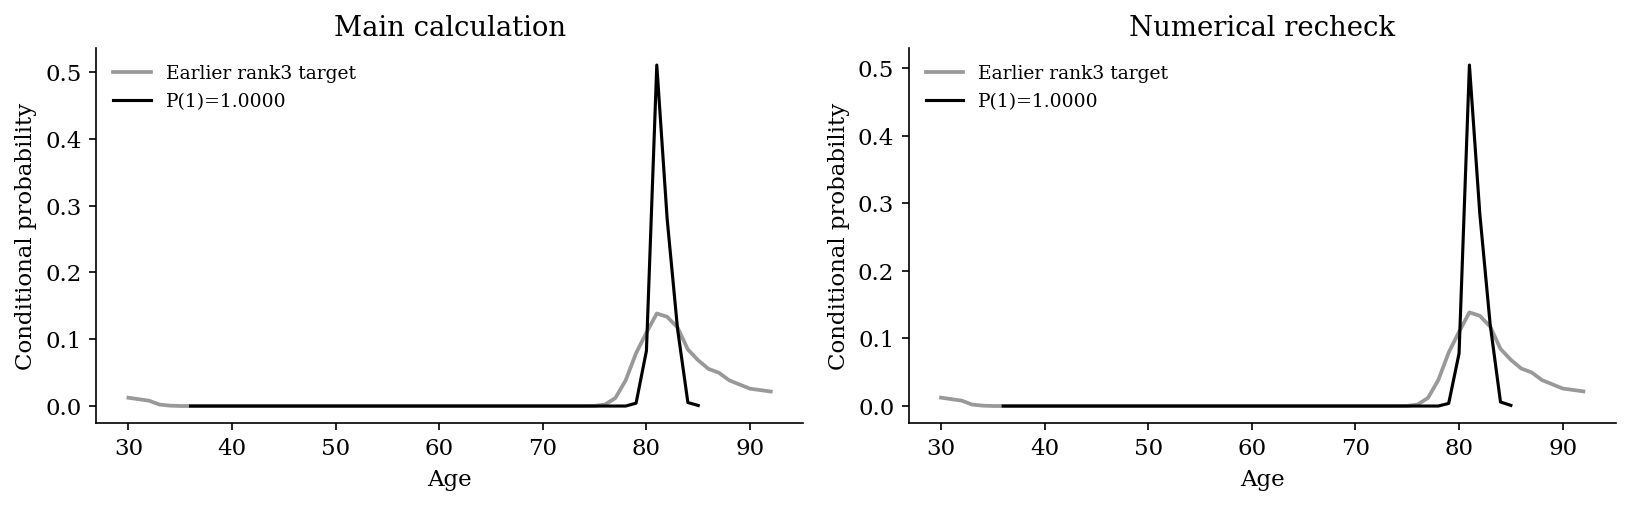

### #2: d20_int1_lbfgs20_rho40_fista16

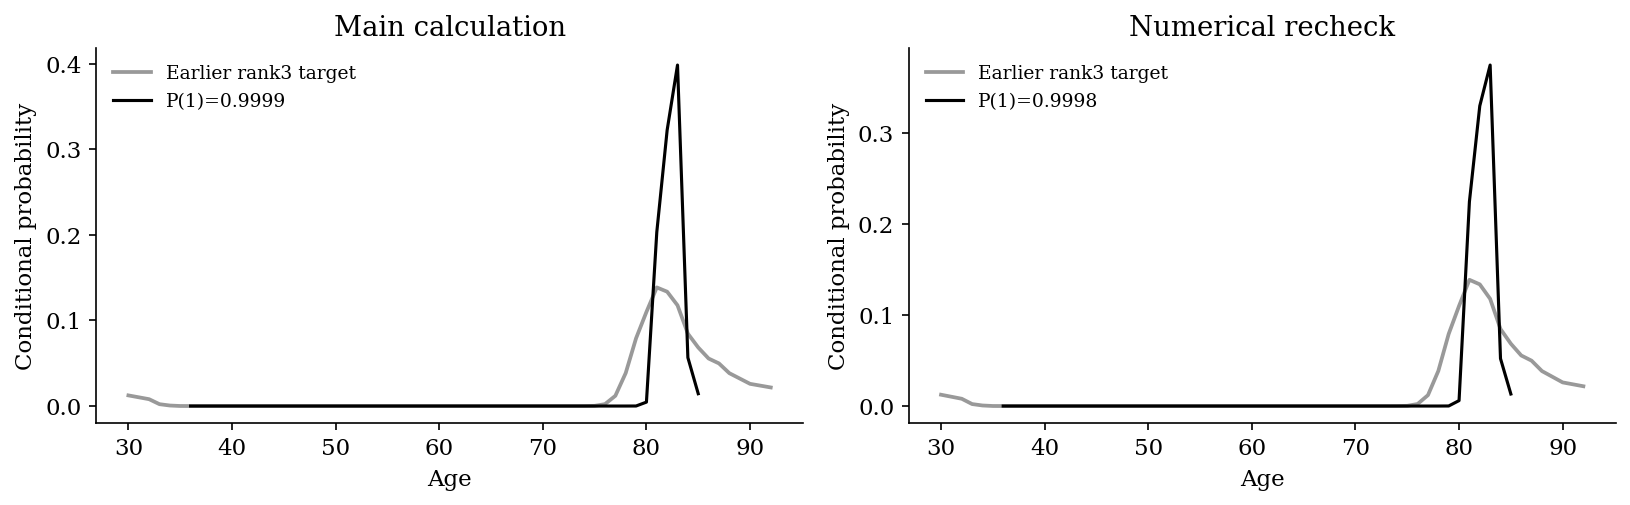

### #3: d20_int1_lbfgs20_rho16_fista16

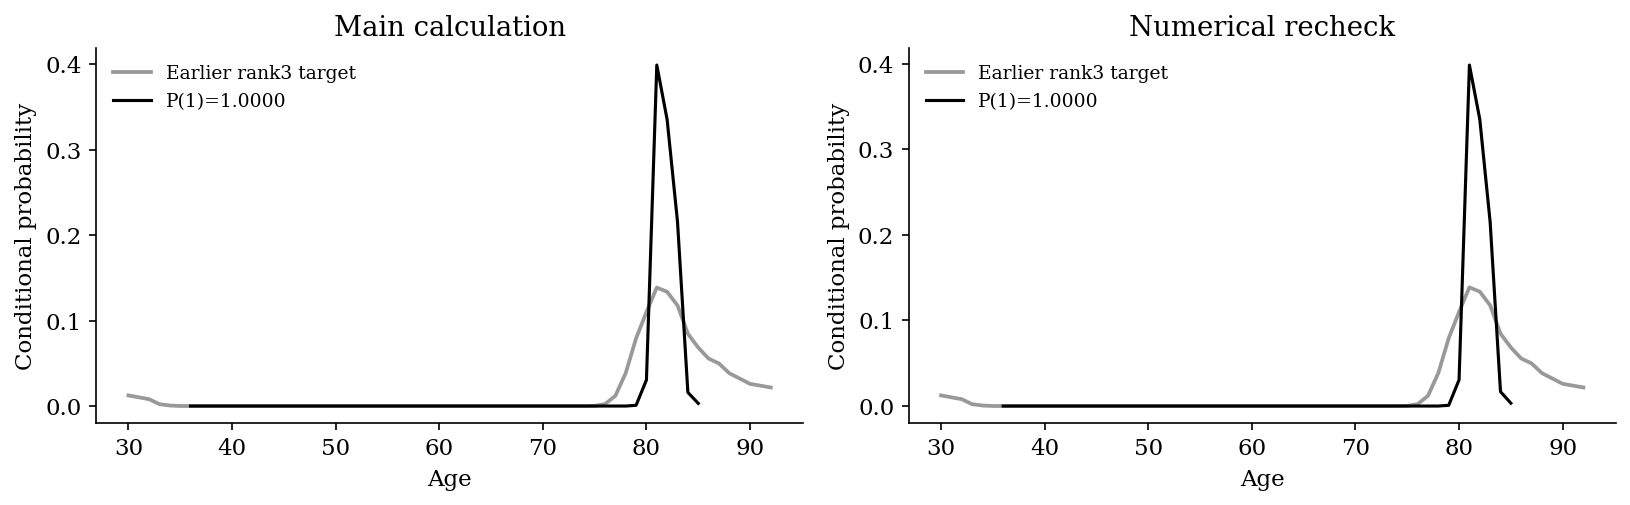

### #4: d20_int1_lbfgs20_rho30_fista16

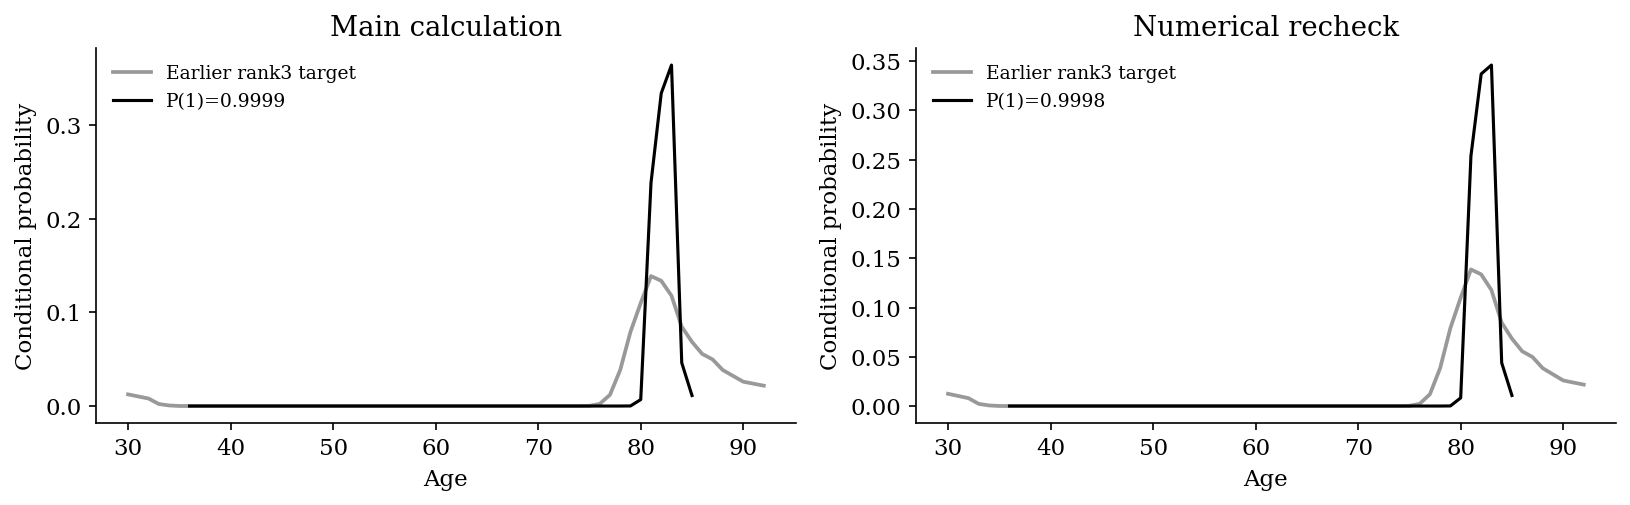

### #5: d20_int1_lbfgs20_rho24_fista16

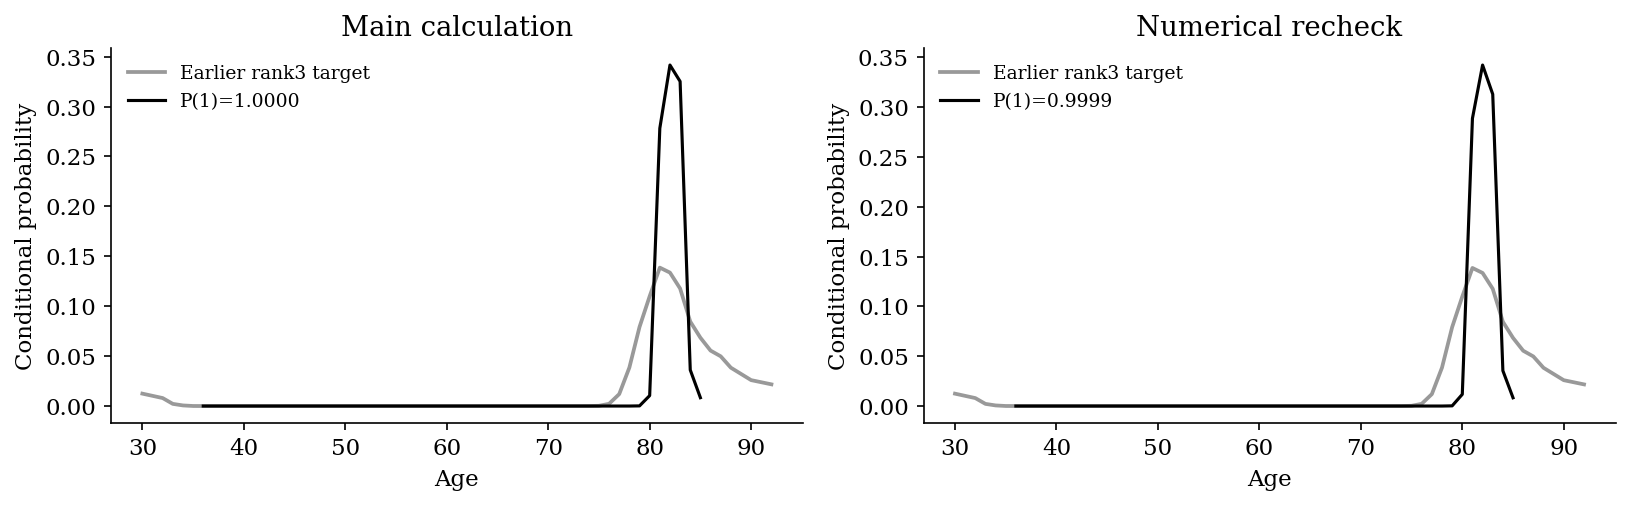

### #6: d20_int1_lbfgs20_rho8_fista16

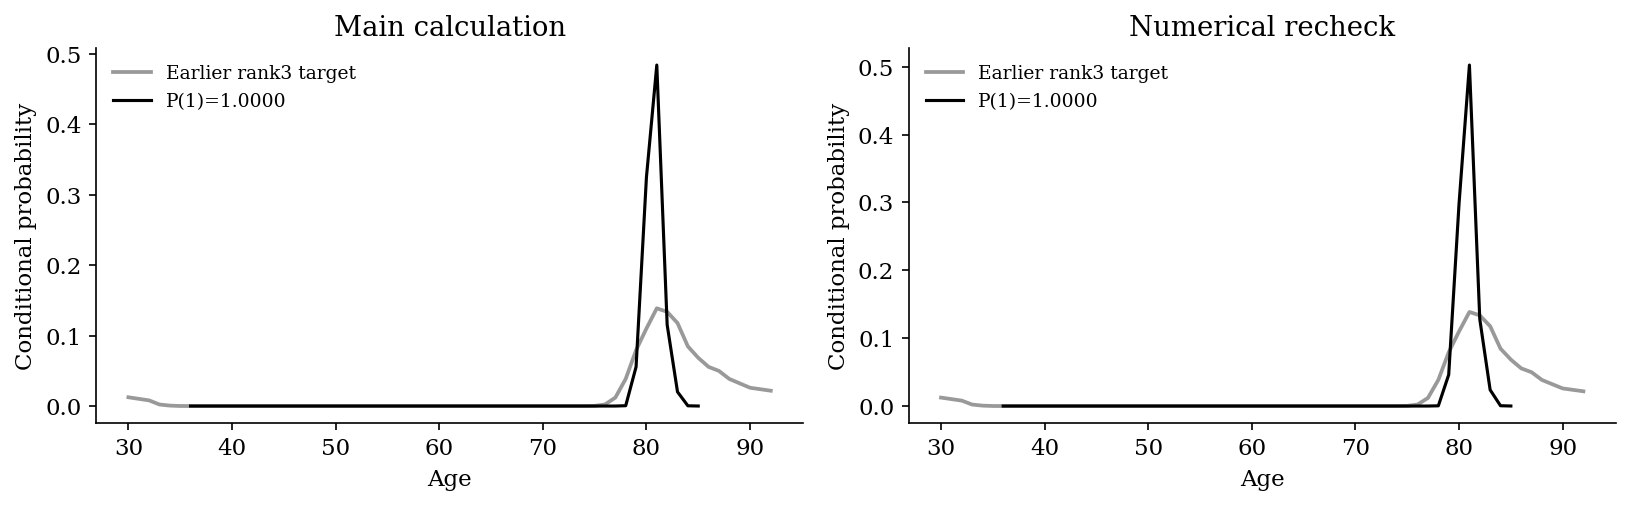

### #7: d20_int1_lbfgs20_rho20_fista16

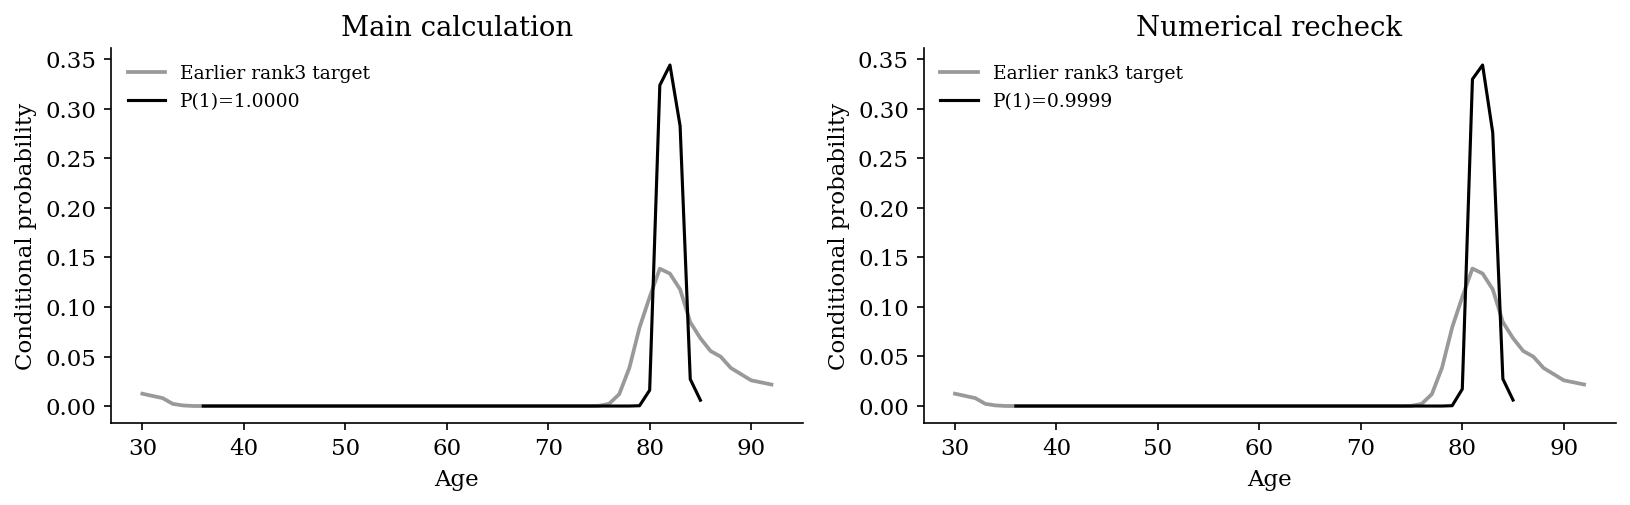

### #8: d1_int1_LS_rho1_fista50

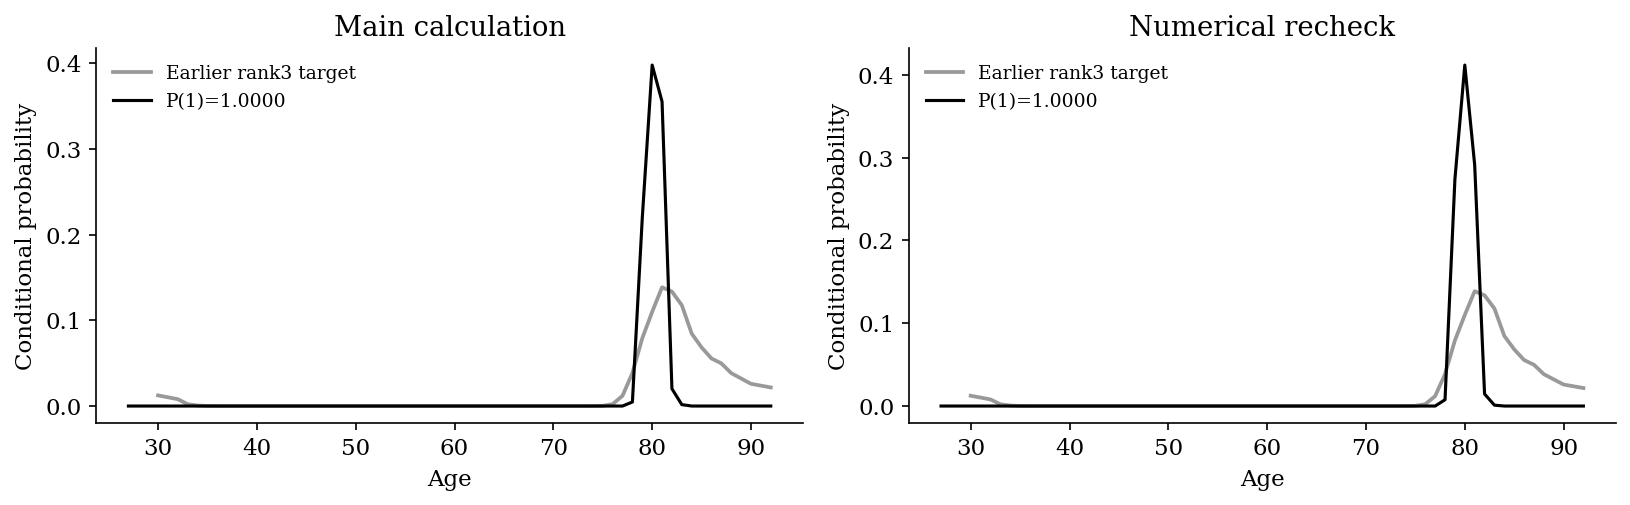

### #9: d2_int1_LS_rho1_fista50

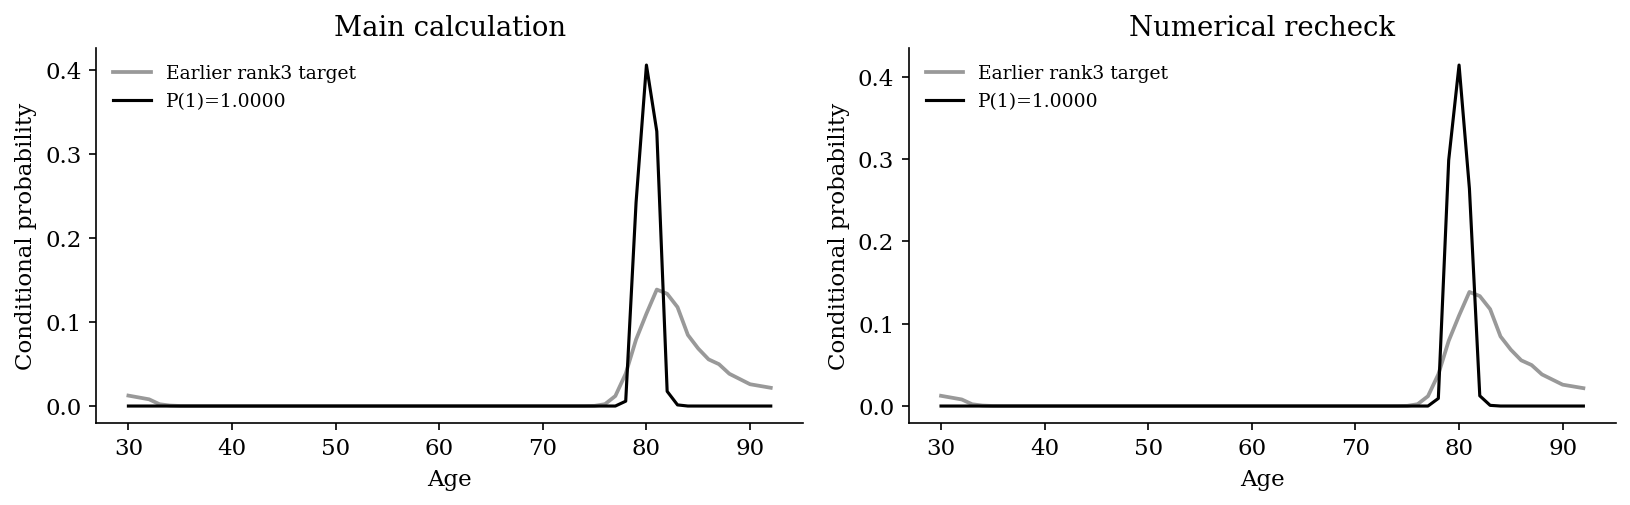

### #10: d20_int1_LS_rho1_fista50

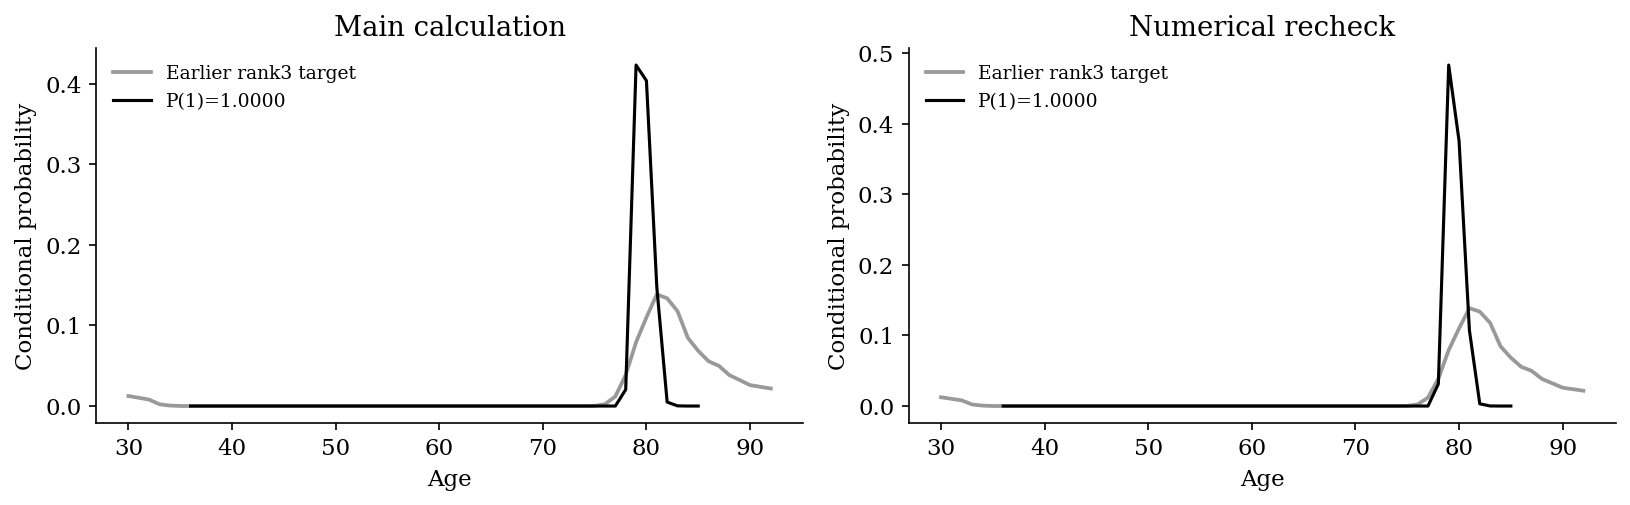

### #11: d20_int0_fista30_rho16_fista30

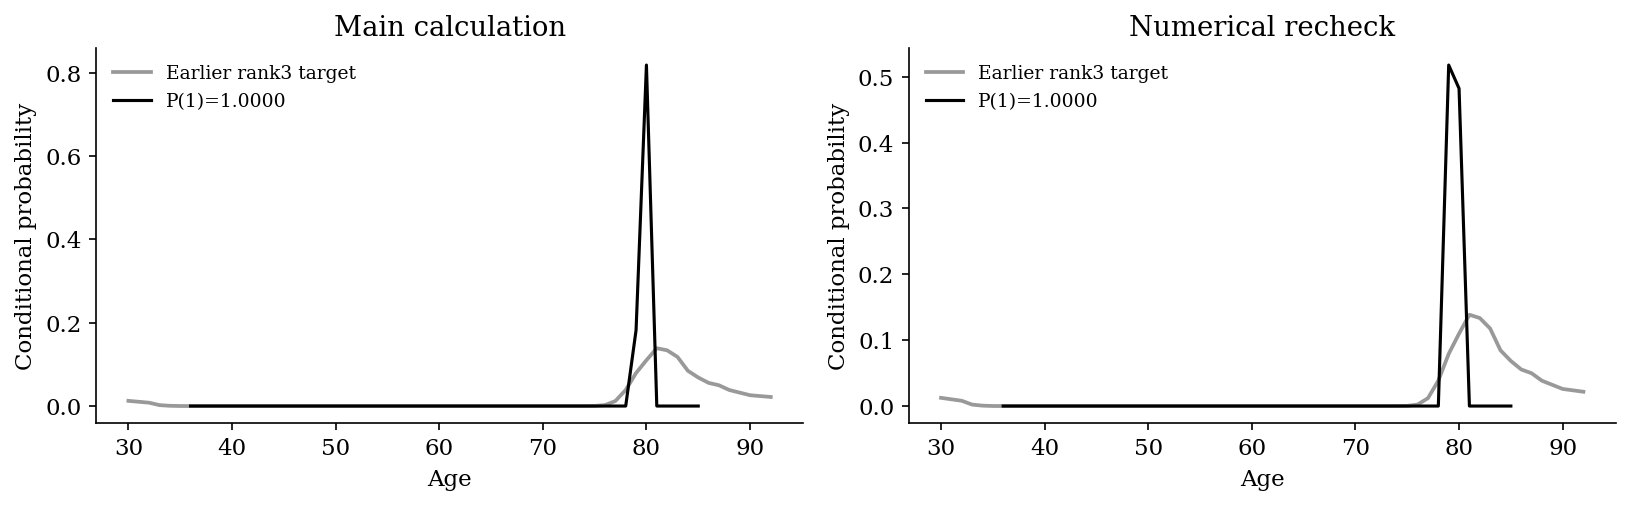

### #12: d10_int0_fista30_rho8_fista30

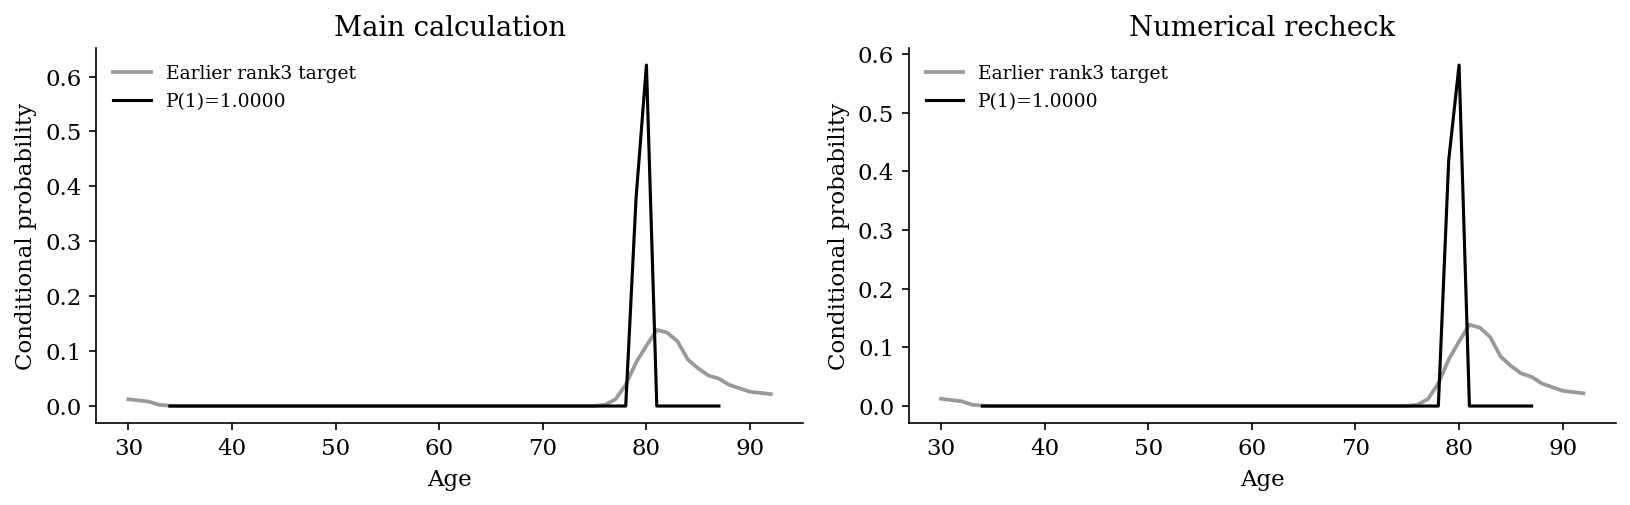

### #13: d1_int0_fista30_rho3_fista30

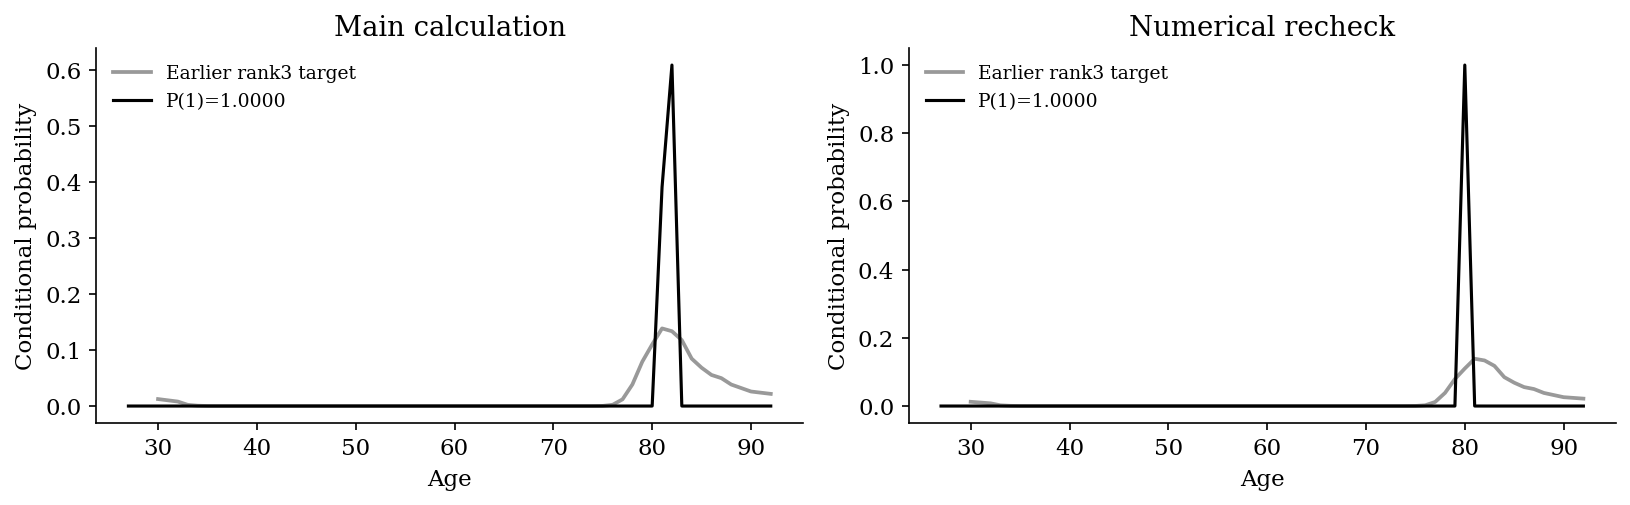

### #14: d2_int0_fista30_rho3_fista30

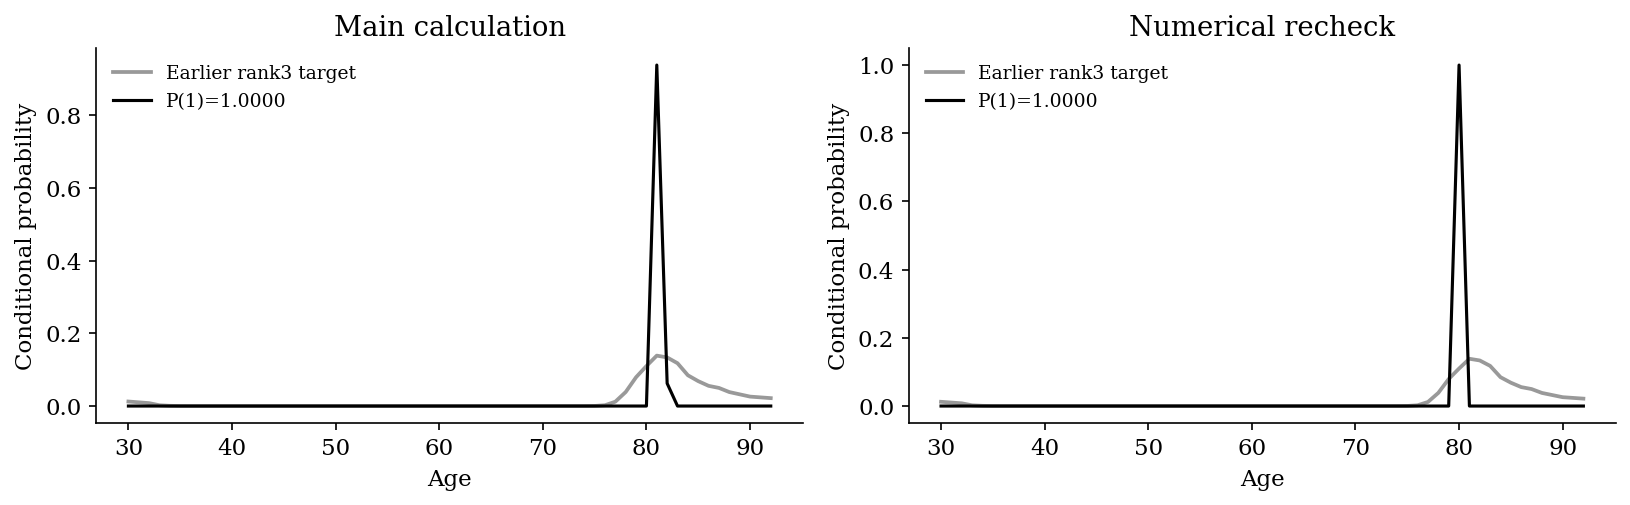

### #15: d20_int0_fista30_rho5_fista30

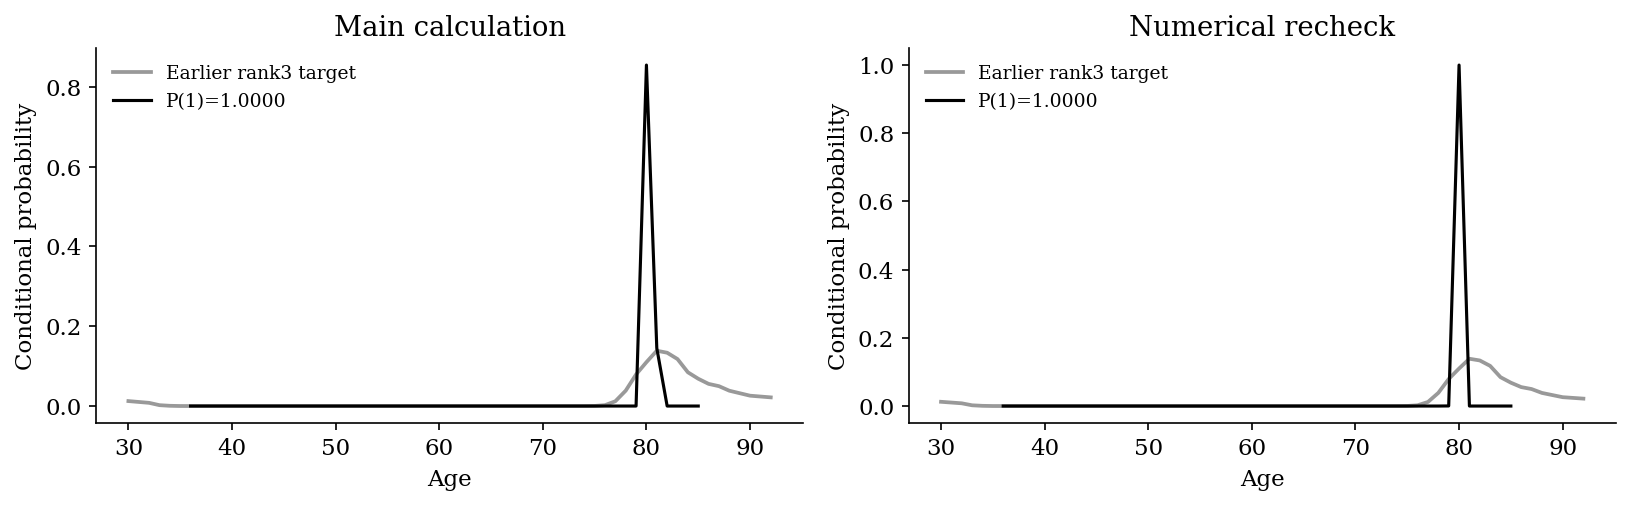

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
summary=pd.read_csv(root/'summary.csv');ranked=pd.read_csv(root/'ranked.csv')
print('All tested outcomes:');display(summary)
print('Top20:');display(ranked.head(20).style.hide(axis='index').format(precision=5))
print('Errors/non-evaluable settings:');display(json.loads((root/'errors.json').read_text()))
target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
def load_result(path,ident):
    saved=pickle.load(open(path,'rb'))
    return next(r for r in saved['results'] if r['id']==ident) if 'results' in saved else saved
for row in ranked.head(20).itertuples():
    a=load_result(row.checkpoint,row.id);b=load_result(row.check_checkpoint,row.id)
    display(Markdown(f'### #{row.rank}: {row.id}'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for ax,r,label in zip(axes,(a,b),('Main calculation','Numerical recheck')):
        ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
        ax.plot(r['ages'],r['conditional'],color='black',lw=1.5,label=f"P(1)={r['P_1']:.4f}")
        ax.set(xlabel='Age',ylabel='Conditional probability',title=label)
        ax.legend(frameon=False,fontsize=9)
    fig.tight_layout();plt.show()
